# Issue #10: Out-of-sample testing

Question: are the strategy's results a product of the parameters we happened to pick, or do they hold up
on data the choice never saw?

**Method.**
- Every combination of three signal parameters is backtested once over the full sample (30 variants,
  grid in `config.yaml` under `robustness`): momentum lookback (63 to 378 days), skip window (0 or 21
  days) and the volatility window used in sizing (20, 60 or 120 days). Sizing, costs, margin and rolls
  are unchanged. Signals, sizing and the backtest only use data up to each date, so slicing one full-sample
  run by date is equivalent to rerunning on that slice.
- **Split test:** parameters are chosen on data before 2019-01-01 and judged on 2019 to 2025.
- **Walk-forward test:** for each year from 2017, pick the variant with the best Sharpe over all earlier
  years (at least 5), then trade that variant for the year. The stitched yearly results are the out-of-sample record.

All figures are daily net returns over the fixed $10M capital, as in `src/analysis.py` (no risk-free rate).
The helper code is in `src/robustness.py`.

**What this test cannot do.** The default (252-day lookback, no skip, 60-day volatility) was chosen
before the backtest, from the literature, but the team has since seen full-sample results in #8, so
the split is not a clean blind test. The 2019 cut-off is a judgement call, and the last table checks how much it matters.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis, backtest, data, portfolio, signals
from src import robustness as rb
from src.config import load_config

cfg = load_config()
rc = cfg["robustness"]
prices = {root: data.build_continuous(data.load_contract_prices(root, cfg["start_date"], cfg["end_date"]), cfg["roll"])
          for root in cfg["universe"]}

COLORS = {"default": "#2a78d6", "best": "#eb6834", "walk": "#1baf7a", "long": "#8d8c85", "es": "#eda100"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False,
})
pd.options.display.float_format = "{:.3f}".format

In [2]:
# About four minutes the first time; reused from results/grid_returns.parquet while the config is unchanged.
grid_returns = rb.load_or_run_grid(prices, cfg, ROOT / "results" / "grid_returns.parquet")
SPLIT = rc["split_date"]
default = rb.label({k: cfg["signal"][k] for k in rc["grid"]})
table = rb.in_vs_out(grid_returns, SPLIT)
best = table["sharpe_in"].idxmax()
print(f"{grid_returns.shape[1]} variants. Default: {default}")
print(f"Best in sample: {best}")

30 variants. Default: lookback_days=252, skip_days=0, vol_lookback_days=60
Best in sample: lookback_days=378, skip_days=0, vol_lookback_days=60


## 1. Does in-sample performance carry over?

In [3]:
summary = pd.DataFrame({
    "in sample": [table.loc[default, "sharpe_in"], table.loc[best, "sharpe_in"], table["sharpe_in"].median()],
    "out of sample": [table.loc[default, "sharpe_out"], table.loc[best, "sharpe_out"], table["sharpe_out"].median()],
}, index=["default", "best in sample", "median of all variants"])
summary["change"] = summary["out of sample"] - summary["in sample"]
print("Sharpe ratio, in sample (to 2018) vs out of sample (2019 to 2025)")
display(summary)
print(f"Variants with a positive Sharpe: {(table.sharpe_in > 0).mean():.0%} in sample, {(table.sharpe_out > 0).mean():.0%} out of sample")
print(f"Rank correlation of in-sample and out-of-sample Sharpe across variants: {rb.rank_correlation(table):.2f}")

Sharpe ratio, in sample (to 2018) vs out of sample (2019 to 2025)


,in sample,out of sample,change
default,0.592,0.054,-0.538
best in sample,0.901,0.473,-0.428
median of all variants,0.544,-0.017,-0.561


Variants with a positive Sharpe: 100% in sample, 50% out of sample
Rank correlation of in-sample and out-of-sample Sharpe across variants: 0.48


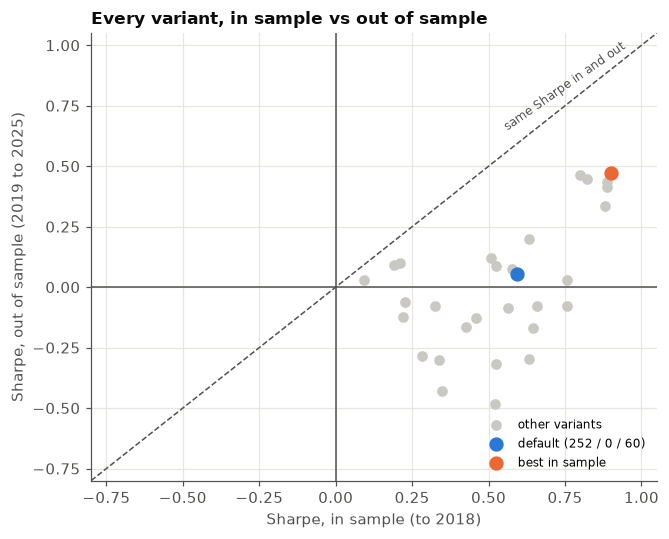

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.scatter(table["sharpe_in"], table["sharpe_out"], s=36, color="#c9c8c2", label="other variants", zorder=2)
for name, key, text in [(default, "default", "default (252 / 0 / 60)"), (best, "best", "best in sample")]:
    ax.scatter(table.loc[name, "sharpe_in"], table.loc[name, "sharpe_out"], s=70, color=COLORS[key], zorder=3, label=text)
lim = [-0.8, 1.05]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.text(0.95, 0.99, "same Sharpe in and out", color=MUTED, fontsize=8, ha="right", rotation=35, rotation_mode="anchor")
ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Sharpe, in sample (to 2018)"); ax.set_ylabel("Sharpe, out of sample (2019 to 2025)")
ax.set_title("Every variant, in sample vs out of sample", loc="left")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); plt.show()

**Findings.**
- The decay is large and affects the whole parameter family, not only the default. The default's Sharpe
  falls from about 0.59 to 0.05, and the median variant's from about 0.54 to -0.02. All 30 variants make money in
  sample; only half do out of sample.
- The ranking carries some information (rank correlation about 0.5), so the in-sample results are not pure noise.
  The best in-sample variant (378-day lookback) is also the best out of sample, at a Sharpe of 0.47.
- Every one of the 30 points lies below the dashed line, so for this split the in-sample results overstate what followed.

## 2. Which parameters matter?

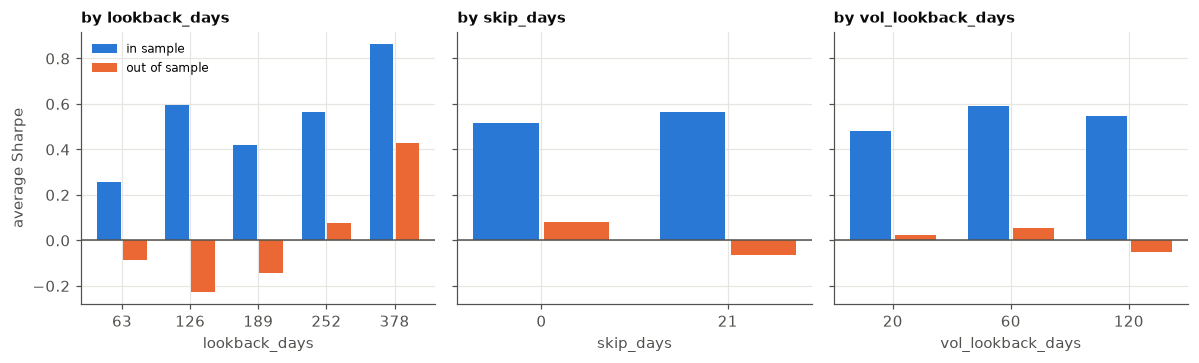

In [5]:
params = table.copy()
for key in rc["grid"]:
    params[key] = [int(name.split(f"{key}=")[1].split(",")[0]) for name in params.index]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, key in zip(axes, rc["grid"]):
    means = params.groupby(key)[["sharpe_in", "sharpe_out"]].mean()
    x = np.arange(len(means)); w = 0.38
    ax.bar(x - w / 2, means["sharpe_in"], w * 0.92, color="#2a78d6", label="in sample")
    ax.bar(x + w / 2, means["sharpe_out"], w * 0.92, color="#eb6834", label="out of sample")
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(x, means.index); ax.set_xlabel(key); ax.set_title(f"by {key}", loc="left", fontsize=10)
axes[0].set_ylabel("average Sharpe"); axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

**Findings.**
- **Lookback is the parameter that matters.** Averaged over the other settings, out-of-sample Sharpe rises with the
  lookback: negative for 63, 126 and 189 days, about 0.08 at 252, and about 0.43 at 378. In sample the pattern is
  noisier but 378 is also the best.
- **378 days is the longest lookback tried.** The best value may lie beyond the grid. Extending the grid would be
  reasonable, but it adds one more search over the same data, so the result would need a fresh hold-out.
- The skip window and the volatility window make little difference (average Sharpe within about 0.15 of each other),
  and neither is consistently better in and out of sample. The 60-day volatility window is fine.

## 3. Against the benchmarks, in and out of sample

In [6]:
capital = float(cfg["sizing"]["capital"])
sig = signals.generate_signals(prices, cfg)
always_long = sig.where(sig.isna(), 1.0)
long_results = backtest.run_backtest(portfolio.size_positions(always_long, prices, cfg), prices, cfg)
compare = pd.DataFrame({
    "default": grid_returns[default],
    "best in sample": grid_returns[best],
    "always long (vol-targeted)": analysis.returns_on_capital(long_results, capital),
    "ES buy-and-hold": analysis.buy_and_hold_returns(prices["ES"], grid_returns.index),
}).dropna()
in_s, out_s = rb.split(compare, SPLIT)
cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown"]
print("Dates on which all four series exist only (from December 2011), so the Sharpe ratios differ slightly from section 1")
print("In sample (to 2018)"); display(analysis.performance_summary(in_s)[cols])
print("Out of sample (2019 to 2025)"); display(analysis.performance_summary(out_s)[cols])

Dates on which all four series exist only (from December 2011), so the Sharpe ratios differ slightly from section 1
In sample (to 2018)


,ann_return,ann_vol,sharpe,max_drawdown
default,0.073,0.109,0.669,-0.353
best in sample,0.098,0.109,0.901,-0.162
always long (vol-targeted),0.105,0.109,0.959,-0.189
ES buy-and-hold,0.119,0.131,0.903,-0.223


Out of sample (2019 to 2025)


,ann_return,ann_vol,sharpe,max_drawdown
default,0.006,0.108,0.054,-0.204
best in sample,0.051,0.107,0.473,-0.260
always long (vol-targeted),0.063,0.108,0.588,-0.188
ES buy-and-hold,0.147,0.196,0.752,-0.391


**Findings.**
- Out of sample, neither momentum variant beats simply staying long with the same volatility targeting
  (Sharpe 0.05 and 0.47, against 0.59). This repeats the in-sample EDA result from #5.
- Momentum did not reduce drawdowns either: the maximum drawdown out of sample is about -20% (default) and
  -26% (best in sample), against -19% for always-long with the same sizing.
- ES buy-and-hold had the highest Sharpe out of sample (0.75), but with 19.6% volatility and a -39% drawdown. The
  volatility-targeted versions run at about 11%.
- So what looks protective in the strategy comes mainly from **volatility targeting**, not from the momentum signal.

## 4. Walk-forward

In [7]:
wf_cfg = rc["walk_forward"]
walk, chosen = rb.walk_forward(grid_returns, wf_cfg["first_test_year"], wf_cfg["min_train_years"])
chosen["variant"] = chosen["variant"].str.replace("lookback_days=", "L=").str.replace("skip_days=", "skip=").str.replace("vol_lookback_days=", "vol=")
display(chosen.astype({"train_sharpe": float, "test_sharpe": float}))
window = walk.index
rows = pd.DataFrame({
    "walk-forward": walk,
    "default": grid_returns.loc[window, default],
    "best in sample (fixed)": grid_returns.loc[window, best],
    "always long (vol-targeted)": compare["always long (vol-targeted)"].reindex(window),
})
print(f"Out of sample, {window.min().date()} to {window.max().date()}")
display(analysis.performance_summary(rows)[cols])
print(f"Median Sharpe of all 30 fixed variants over the same window: {rb.sharpe(grid_returns.loc[window]).median():.3f}")

,variant,train_sharpe,test_sharpe
2017,"L=378, skip=0, vol_L=120",0.837,3.213
2018,"L=378, skip=0, vol_L=120",1.207,-0.295
2019,"L=378, skip=0, vol_L=60",0.901,1.245
2020,"L=378, skip=21, vol_L=120",0.942,0.075
2021,"L=378, skip=0, vol_L=60",0.912,1.368
2022,"L=378, skip=0, vol_L=60",0.956,-1.297
2023,"L=378, skip=0, vol_L=60",0.755,0.045
2024,"L=378, skip=0, vol_L=60",0.704,0.809
2025,"L=378, skip=0, vol_L=60",0.712,0.422


Out of sample, 2017-01-03 to 2025-12-31


,ann_return,ann_vol,sharpe,max_drawdown
walk-forward,0.059,0.114,0.517,-0.260
default,0.044,0.111,0.398,-0.299
best in sample (fixed),0.076,0.111,0.682,-0.260
always long (vol-targeted),0.083,0.111,0.743,-0.189


Median Sharpe of all 30 fixed variants over the same window: 0.299


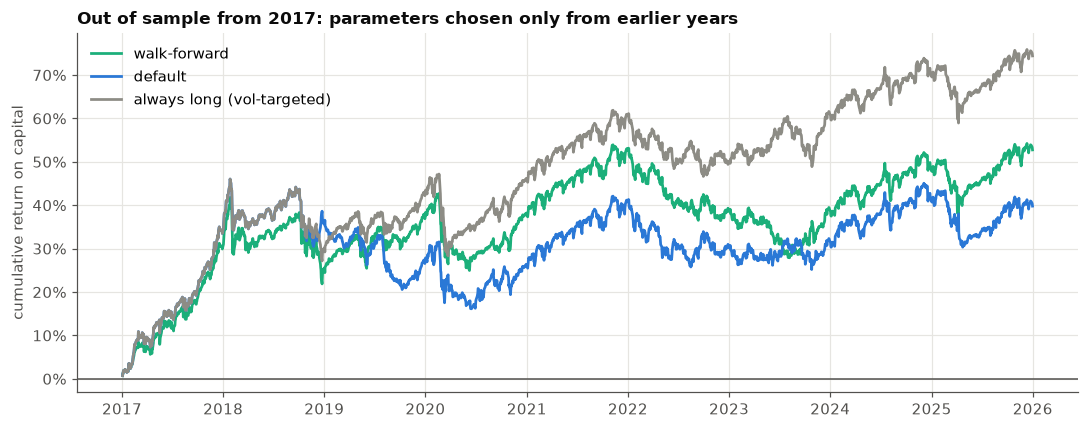

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, color in [("walk-forward", COLORS["walk"]), ("default", COLORS["default"]),
                    ("always long (vol-targeted)", COLORS["long"])]:
    wealth = rows[name].cumsum()
    ax.plot(wealth.index, wealth, color=color, lw=1.8, label=name)
ax.axhline(0, color=MUTED, lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("cumulative return on capital")
ax.set_title("Out of sample from 2017: parameters chosen only from earlier years", loc="left")
ax.legend(loc="upper left")
fig.tight_layout(); plt.show()

**Findings.**
- Choosing parameters from past data worked here: the walk-forward Sharpe from 2017 to 2025 is about 0.52, against about 0.40
  for the default and 0.30 for the median fixed variant over the same window.
- It picks the 378-day lookback every year, with no skip (except 2020) and a 60- or 120-day volatility window.
  378 is the edge of the grid, and this is the same finding as section 2, not independent confirmation.
- It still trails staying long: always-long with the same sizing has a Sharpe of about 0.74 over the same years, and a
  -19% maximum drawdown against -26%.
- The yearly results are volatile (Sharpe about +3.2 in 2017, -1.3 in 2022), so nine years is a short record.

Both tests find that the momentum signal added little beyond volatility targeting.

## 5. Does the split date matter?

In [9]:
rows = {}
for year in [2016, 2017, 2018, 2019, 2020, 2021]:
    t = rb.in_vs_out(grid_returns, f"{year}-01-01")
    pick = t["sharpe_in"].idxmax()
    rows[f"{year}-01-01"] = {
        "default in": t.loc[default, "sharpe_in"], "default out": t.loc[default, "sharpe_out"],
        "median out": t["sharpe_out"].median(),
        "best-in variant out": t.loc[pick, "sharpe_out"], "best-in lookback": int(pick.split("=")[1].split(",")[0]),
        "rank corr": rb.rank_correlation(t),
    }
display(pd.DataFrame(rows).T)

,default in,default out,median out,best-in variant out,best-in lookback,rank corr
2016-01-01,0.400,0.309,0.230,0.519,378.000,0.604
2017-01-01,0.235,0.398,0.299,0.561,378.000,0.430
2018-01-01,0.684,0.070,-0.014,0.292,378.000,0.436
2019-01-01,0.592,0.054,-0.017,0.473,378.000,0.481
2020-01-01,0.437,0.196,0.077,0.180,378.000,0.479
2021-01-01,0.379,0.254,0.047,0.274,378.000,0.690


**Findings.** The size of the decay depends on the cut-off, so the 2019 split is the harshest of the six.
- The default's out-of-sample Sharpe is lower than its in-sample Sharpe at five of the six cut-offs (2016, 2018, 2019,
  2020, 2021) and higher at 2017 (0.40 against 0.24). It ranges from 0.05 to 0.40, always positive but small.
- The 2018 and 2019 cut-offs give the biggest drop because the in-sample window then includes the strong years 2013 and 2017.
- The best-in-sample variant is the 378-day lookback at every cut-off, with an out-of-sample Sharpe between 0.18 and 0.56.
- The rank correlation between in-sample and out-of-sample Sharpe is 0.43 to 0.69 throughout, so the ranking has some
  predictive value at every cut-off.

## 6. Summary for the report

1. **The default is weak out of sample, and how weak depends on the cut-off.** Sharpe 0.59 in sample (to 2018) against 0.05 in
   2019 to 2025. Over six cut-offs from 2016 to 2021 its out-of-sample Sharpe ranges from 0.05 to 0.40. The decay is across the
   whole grid (median 0.54 to -0.02 at the 2019 split), which points to the strategy and not to a bad parameter choice.
2. **A longer lookback has held up better**, in sample and out of sample (378 days: Sharpe 0.47 out of sample). The grid ends there,
   so this needs a fresh hold-out before it is adopted.
3. **Momentum did not beat staying long** with the same volatility targeting, in sample or out, and did not reduce drawdowns out of sample.
   The risk control comes from volatility targeting.
4. **Walk-forward selection helped modestly** (Sharpe 0.52 against 0.40 for the default), mostly by moving to the longer lookback.
5. **Limits:** one 14-year sample, splits chosen by hand, a grid of 30 variants searched on the same data, and no sensitivity
   analysis yet of costs, margin or roll costs (the remaining #10 tasks).